In [2]:
import os
import sys
import numpy as np

module_path = os.path.abspath(os.path.join('..', ''))
if module_path not in sys.path:
    sys.path.append(module_path)

from rect_prune_ood.lib.util.paths import get_top_level_path

#paths to saved activations and results
results_dir = os.path.join(get_top_level_path(), 'results')
imagenet_c_results_dir = os.path.join(results_dir, 'imagenet', "baseline", "imagenet_c")
ablation_study_results_dir = os.path.join(results_dir, 'ablation_study_pertubation')
os.makedirs(ablation_study_results_dir, exist_ok=True)

#possible perturbations from imagenetc
imagenet_c_pertubations = [
        "gaussian_noise", 
        "saturate",
        "brightness",
        "pixelate",
        "snow",
        "motion_blur",
        "elastic_transform",
        "fog",
        "zoom_blur",
        "shot_noise",
        "contrast",
        "defocus_blur",
        "frost",
        "impulse_noise",
        "jpeg_compression",
        "glass_blur",
    ]


#sortet perturbations by how they occur in the file system
imagenet_c_pertubations_file = [
        "brightness",
        "defocus_blur",
        "fog",
        "gaussian_blur",
        "glass_blur",
        "jpeg_compression",
        "pixelate",
        "shot_noise",
        "spatter",
        "zoom_blur",
        "contrast",
        "elastic_transform",
        "frost",
        "gaussian_noise", 
        "impulse_noise",
        "motion_blur",
        "saturate",
        "snow",
        "speckle_noise"
    ]

In [3]:
from torch.nn import Module
from torch import Tensor

#reimplemntation of APES to pass a mask which saves time in this setting
class APESP(Module):
    def __init__(self, mask) -> None:
        #super(LayerScaler, self).__init__()
        super(APESP, self).__init__()
        self.mask = mask
        
    
    def forward(self, x: Tensor) -> Tensor:
        x = self.apes_p(x)
        return x
    
    def apes_p(self, x):
        assert x.dim() == 4
        _, c, _, _ = x.shape
        assert self.mask.shape[0] == c 

        x = x * self.mask

        return x

In [4]:
import os
import numpy as np

#activations for imagenet_c
imagenet_c_activations_path = os.path.join('/fastdata', 'vilab17', 'imagenet_c_activations_severity_1.npy')
imagenet_c_activations = np.load(imagenet_c_activations_path)

In [ ]:
import torch
from lightning import Trainer
from rect_prune_ood.lib.experiments.feature_extractor import FeatureExtractor
from rect_prune_ood.lib.experiments.backbones import get_resnet50
from rect_prune_ood.lib.experiments.pipeline import Pipeline
from rect_prune_ood.lib.util.data_loader import get_data_loader

masks = []

#for all perturbations
for i in range(len(imagenet_c_pertubations_file)):
    #get desired activations
    activations = imagenet_c_activations[i]

    #calculate variance
    variance = np.var(activations, axis=1)
    variance = torch.tensor(variance)
    #calc mask
    percentile = np.percentile(variance, 95)

    mask = torch.where(variance <= percentile, 1, 0)
    mask = mask.view(variance.shape[0], 1, 1).cuda()


    #################
    ### ImageNet ####
    #################
    #same procedure as in single experiment call
    feature_extractor = FeatureExtractor(get_resnet50(), 'avgpool')
    
    fc_layer = feature_extractor.get_fc_layer()

    pipeline = Pipeline(feature_extractor, 'baseline', fc_layer, caputure_activations=False)
    pipeline.method_list = [APESP(mask)]

    dataloader, _ = get_data_loader('imagenet', batch_size=16)

    # Trainer
    trainer = Trainer(logger=None)
    trainer.test(pipeline, dataloader)

    results = pipeline.results
    #save results for each perturbation
    np.save(os.path.join(ablation_study_results_dir, f"ID_results_{imagenet_c_pertubations_file[i]}.npy"), results)

    ####################
    ### OpenImage-O ####
    ####################

    feature_extractor = FeatureExtractor(get_resnet50(), 'avgpool')
    
    fc_layer = feature_extractor.get_fc_layer()

    pipeline = Pipeline(feature_extractor, 'baseline', fc_layer, caputure_activations=False)
    pipeline.method_list = [APESP(mask)]
    #evaluate for all datasets
    datasets = ["inat", "places", "sun", "dtd", "openimage-o", "ninco", "ssb_hard"]
    for dataset in datasets:
        dataloader, _ = get_data_loader(dataset, batch_size=16)

        # Trainer
        trainer = Trainer(logger=None)
        trainer.test(pipeline, dataloader)

        results = pipeline.results

        np.save(os.path.join(ablation_study_results_dir, f"{dataset}_results_{imagenet_c_pertubations_file[i]}.npy"), results)

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
/visinf/home/vilab18/miniforge3/envs/rectPruneEnv/lib/python3.13/site-packages/lightning/pytorch/trainer/connectors/logger_connector/logger_connector.py:75: Starting from v1.9.0, `tensorboardX` has been removed as a dependency of the `lightning.pytorch` package, due to potential conflicts with other packages in the ML ecosystem. For this reason, `logger=True` will use `CSVLogger` as the default logger, unless the `tensorboard` or `tensorboardX` packages are found. Please `pip install lightning[extra]` or one of them to enable TensorBoard support by default
You are using a CUDA device ('NVIDIA GeForce RTX 3080 Ti') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_prec

Testing: |          | 0/? [00:00<?, ?it/s]

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Testing: |          | 0/? [00:00<?, ?it/s]

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Testing: |          | 0/? [00:00<?, ?it/s]

... (294 outputs left out)

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Testing: |          | 0/? [00:00<?, ?it/s]

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Testing: |          | 0/? [00:00<?, ?it/s]

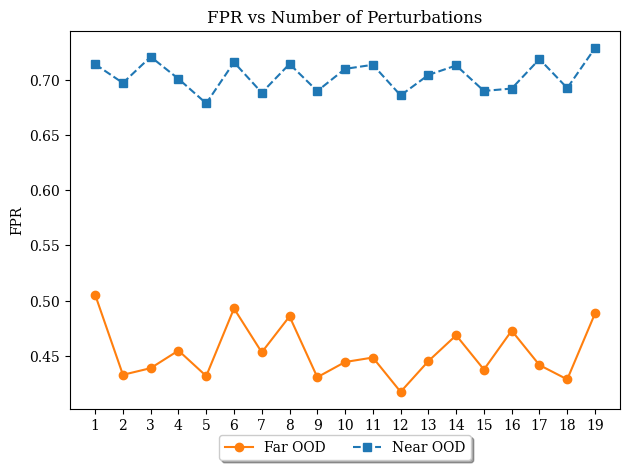

In [7]:
import matplotlib.pyplot as plt
import random
from rect_prune_ood.lib.eval.metrics import *


#get all results that were saved
all_results = {}
metric = "FPR"
score_function = "energy_score"

#random indices for unbiased study effect, seed same as in paper
random_indices = [14, 5, 2, 15, 4, 17, 18, 13, 11, 12, 16, 8, 10, 7, 3, 1, 6, 0, 9]
#for ri in random_indices:
#    print(imagenet_c_pertubations_file[ri])

#get metrics for each perturbation for each dataset
for i in random_indices:
    perturbation_results = {}

    imagenet_scores = np.load(os.path.join(ablation_study_results_dir, f"ID_results_{imagenet_c_pertubations_file[i]}.npy"), allow_pickle=True).item()[score_function]
    datasets = ["inat", "places", "sun", "dtd", "openimage-o", "ninco", "ssb_hard"]
    for dataset in datasets:
        ood_scores = np.load(os.path.join(ablation_study_results_dir, f"{dataset}_results_{imagenet_c_pertubations_file[i]}.npy"), allow_pickle=True).item()[score_function]

        perturbation_results[dataset] = cal_metric(imagenet_scores, ood_scores)
        

    all_results[imagenet_c_pertubations_file[i]] = perturbation_results

plt.rcParams.update({
    "text.usetex": False,
    "font.family": "serif"
})


#plot results of analysis
fig, ax1 = plt.subplots()

inat_vals = []
places_vals = []
sun_vals = []
dtd_vals = []
openimage_o_vals = []
ninco_vals = []
ssb_hard_vals = []

far_ood_vals = []
near_ood_vals = []

for perturbation in all_results.keys():
    inat_vals.append(all_results[perturbation]["inat"][metric])
    places_vals.append(all_results[perturbation]["places"][metric])
    sun_vals.append(all_results[perturbation]["sun"][metric])
    dtd_vals.append(all_results[perturbation]["dtd"][metric])
    openimage_o_vals.append(all_results[perturbation]["openimage-o"][metric])
    ninco_vals.append(all_results[perturbation]["ninco"][metric])
    ssb_hard_vals.append(all_results[perturbation]["ssb_hard"][metric])

    far_ood_vals.append((all_results[perturbation]["inat"][metric] + all_results[perturbation]["places"][metric] + 
                         all_results[perturbation]["sun"][metric] + all_results[perturbation]["dtd"][metric] + all_results[perturbation]["openimage-o"][metric]) / 5)
    near_ood_vals.append((all_results[perturbation]["ninco"][metric] + all_results[perturbation]["ssb_hard"][metric]) / 2)


plot_ood_class_average = True

ax1.set_xticks(range(1, 20))
if plot_ood_class_average:
    ax1.plot(np.arange(1, 20), far_ood_vals, marker='o', linestyle='-', color="tab:orange", label="Far OOD")
    ax1.plot(np.arange(1, 20), near_ood_vals, marker='s', linestyle='--', color="tab:blue", label="Near OOD")

else:
    ax1.plot(np.arange(1, 20), inat_vals, marker='o', linestyle='-', color="tab:orange", label="inat")
    ax1.plot(np.arange(1, 20), places_vals, marker='s', linestyle='--', color="tab:blue", label="places")
    ax1.plot(np.arange(1, 20), sun_vals, marker='^', linestyle=':', color="tab:green", label="sun")
    ax1.plot(np.arange(1, 20), dtd_vals, marker='P', linestyle='-.', color="tab:red", label="dtd")
    ax1.plot(np.arange(1, 20), openimage_o_vals, marker='D', linestyle='-', color="tab:purple", label="openimage-o")
    ax1.plot(np.arange(1, 20), ninco_vals, marker='X', linestyle='--', color="tab:brown", label="ninco")
    ax1.plot(np.arange(1, 20), ssb_hard_vals, marker='*', linestyle=':', color="tab:pink", label="ssb_hard")

#set legend below graph
ax1.legend(loc='upper center', bbox_to_anchor=(0.5, -0.05),
          fancybox=True, shadow=True, ncol=3)
# Left y-axis for AUROC
ax1.set_xlabel("Number of Perturbations")
ax1.set_ylabel(metric)


plt.title(f"{metric} vs Number of Perturbations")
fig.tight_layout()
pdf_path = os.path.join(ablation_study_results_dir, f"num_perturbations_{metric}_plot.pdf")
#plt.savefig(pdf_path, format="pdf")
plt.show()

In [31]:
random_indices = [14, 5, 2, 15, 4, 17, 18, 13, 11, 12, 16, 8, 10, 7, 3, 1, 6, 0, 9]
for ri in random_indices:
    print(imagenet_c_pertubations_file[ri])
#for i in range(len(imagenet_c_pertubations_file)):
scores = []
for i in random_indices:

    imagenet_scores = np.load(os.path.join(ablation_study_results_dir, f"ID_results_{imagenet_c_pertubations_file[i]}.npy"), allow_pickle=True).item()["energy_score"]
    
    dataset = "openimage-o"
    ood_scores = np.load(os.path.join(ablation_study_results_dir, f"{dataset}_results_{imagenet_c_pertubations_file[i]}.npy"), allow_pickle=True).item()["energy_score"]

    scores.append(cal_metric(imagenet_scores, ood_scores)["AUROC"].item())
print(scores)

sorted_indices = np.argsort(scores)[::-1]

scores = np.array(scores)[sorted_indices]
random_indices = np.array(random_indices)[sorted_indices]

print(scores)
print([imagenet_c_pertubations_file[i] for i in random_indices])

impulse_noise
jpeg_compression
fog
motion_blur
glass_blur
snow
speckle_noise
gaussian_noise
elastic_transform
frost
saturate
spatter
contrast
shot_noise
gaussian_blur
defocus_blur
pixelate
brightness
zoom_blur
[0.8650163679673322, 0.863434926837568, 0.8687530507032668, 0.8685383110254083, 0.8689545258620689, 0.8590979038112523, 0.8666298712568058, 0.8628225680580762, 0.8701604968239564, 0.8533585344827586, 0.8597357815335752, 0.8660642655399274, 0.8652043767014519, 0.8664730393602541, 0.8729274103901997, 0.8744857236842106, 0.8627339156079856, 0.8661352047413794, 0.8716335838248638]
[0.87448572 0.87292741 0.87163358 0.8701605  0.86895453 0.86875305
 0.86853831 0.86662987 0.86647304 0.8661352  0.86606427 0.86520438
 0.86501637 0.86343493 0.86282257 0.86273392 0.85973578 0.8590979
 0.85335853]
['defocus_blur', 'gaussian_blur', 'zoom_blur', 'elastic_transform', 'glass_blur', 'fog', 'motion_blur', 'speckle_noise', 'shot_noise', 'brightness', 'spatter', 'contrast', 'impulse_noise', 'jpeg_co